In [1]:
import numpy as np
from pathlib import Path

DATA = Path("~/Desktop/neural_data").expanduser()
files = sorted(DATA.rglob("*.npz"))
print(len(files), "files")

d = np.load(files[0])
print(files[0].name)
for k in d.files:
    print(k, d[k].shape, d[k].dtype)

print("train_idx first 10:", d["train_idx"][:10])
print("binned_mua min / max / mean:", d["binned_mua"].min(), d["binned_mua"].max(), d["binned_mua"].mean())

12 files
monkeyN_day1_IT_binned.npz
binned_mua (20, 9176, 256) float32
train_idx (9176,) int64
train_idx first 10: [16504 16470 15094  2514  4860  7629 16848 14786  6286  6200]
binned_mua min / max / mean: 1.2739692 197.02597 13.902803


In [2]:
idx = {}
for f in files:
    d = np.load(f)
    _, day, area, _ = f.stem.split("_")
    idx[(day, area)] = d["train_idx"]
    print(f.stem, d["binned_mua"].shape)

days = sorted({k[0] for k in idx})
for day in days:
    same = all(np.array_equal(idx[(day, "V1")], idx[(day, a)]) for a in ["V4", "IT"])
    print(day, "V1/V4/IT same train_idx:", same)

all_idx = np.concatenate([idx[(day, "IT")] for day in days])
print("total trials:", len(all_idx), " unique:", len(np.unique(all_idx)),
      " min/max:", all_idx.min(), all_idx.max())
print("covers exactly 1..22248:", np.array_equal(np.sort(all_idx), np.arange(1, 22249)))

monkeyN_day1_IT_binned (20, 9176, 256)
monkeyN_day1_V1_binned (20, 9176, 512)
monkeyN_day1_V4_binned (20, 9176, 256)
monkeyN_day2_IT_binned (20, 5855, 256)
monkeyN_day2_V1_binned (20, 5855, 512)
monkeyN_day2_V4_binned (20, 5855, 256)
monkeyN_day3_IT_binned (20, 4602, 256)
monkeyN_day3_V1_binned (20, 4602, 512)
monkeyN_day3_V4_binned (20, 4602, 256)
monkeyN_day4_IT_binned (20, 2615, 256)
monkeyN_day4_V1_binned (20, 2615, 512)
monkeyN_day4_V4_binned (20, 2615, 256)
day1 V1/V4/IT same train_idx: True
day2 V1/V4/IT same train_idx: True
day3 V1/V4/IT same train_idx: True
day4 V1/V4/IT same train_idx: True
total trials: 22248  unique: 22248  min/max: 1 22248
covers exactly 1..22248: True


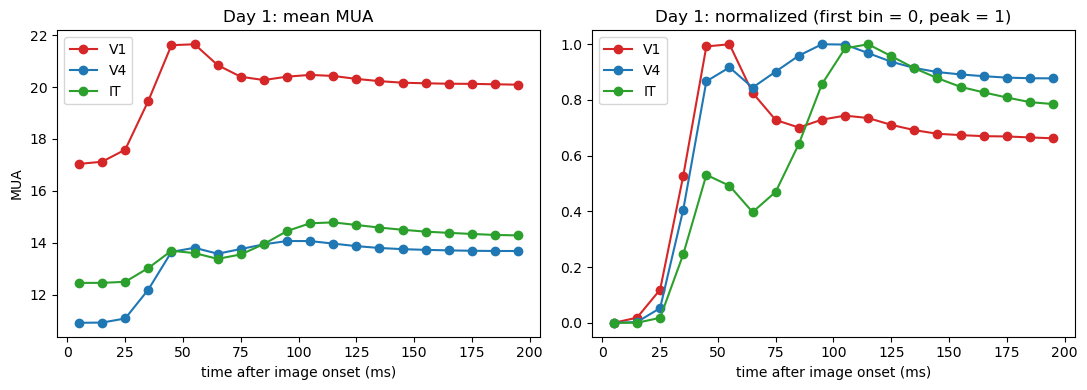

In [ ]:
import matplotlib.pyplot as plt

t_ms = np.arange(20) * 10 + 5  # centers of bins
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for area, color in [("V1", "tab:red"), ("V4", "tab:blue"), ("IT", "tab:green")]:
    mua = np.load(DATA.rglob(f"monkeyN_day1_{area}_binned.npz").__next__())["binned_mua"]
    curve = mua.mean(axis=(1, 2))  # average across all trials and electrodes
    axes[0].plot(t_ms, curve, "o-", color=color, label=area)
    axes[1].plot(t_ms, (curve - curve[0]) / (curve.max() - curve[0]), "o-", color=color, label=area)

axes[0].set(title="Day 1: mean MUA", xlabel="time after image onset (ms)", ylabel="MUA")
axes[1].set(title="Day 1: normalized (first bin = 0, peak = 1)", xlabel="time after image onset (ms)")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

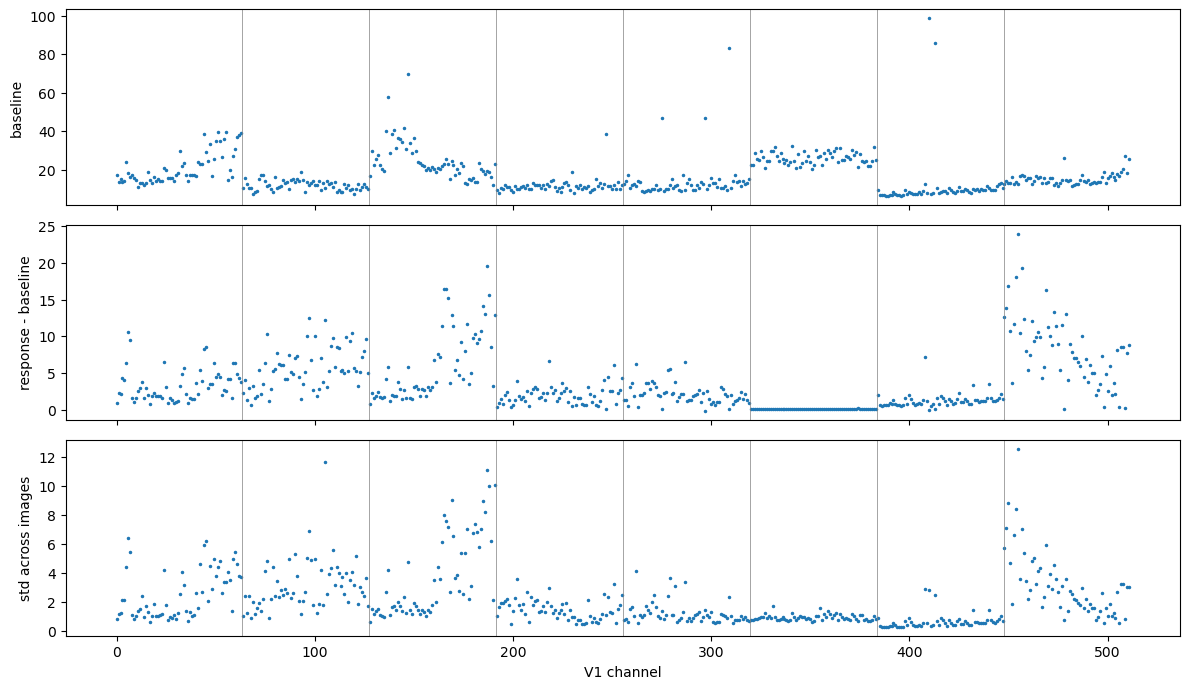

10 weakest channels: [297 410 335 413 247 326 478 360 350 329] [-0.26 -0.    0.06  0.07  0.07  0.07  0.07  0.07  0.08  0.08]
channels with response <= 0: 2


In [4]:
v1 = np.load(next(DATA.rglob("monkeyN_day1_V1_binned.npz")))["binned_mua"]

base = v1[:2].mean(axis=(0, 1))              # 每个通道的基线：0–20 ms
resp = v1[3:11].mean(axis=(0, 1)) - base     # 每个通道的平均反应：30–110 ms 减去基线
spread = v1[3:11].mean(axis=0).std(axis=0)   # 每个通道在不同图片之间的波动

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, y, name in zip(axes, [base, resp, spread], ["baseline", "response - baseline", "std across images"]):
    ax.plot(y, ".", ms=3)
    ax.set_ylabel(name)
    for x in range(64, 512, 64):
        ax.axvline(x - 0.5, color="gray", lw=0.5)
axes[-1].set_xlabel("V1 channel")
plt.tight_layout()
plt.show()

print("10 weakest channels:", np.argsort(resp)[:10], np.round(np.sort(resp)[:10], 2))
print("channels with response <= 0:", (resp <= 0).sum())


day1 channels 320-383: max |response| = 0.149
day2 channels 320-383: max |response| = 0.163
day3 channels 320-383: max |response| = 0.153
day4 channels 320-383: max |response| = 0.199


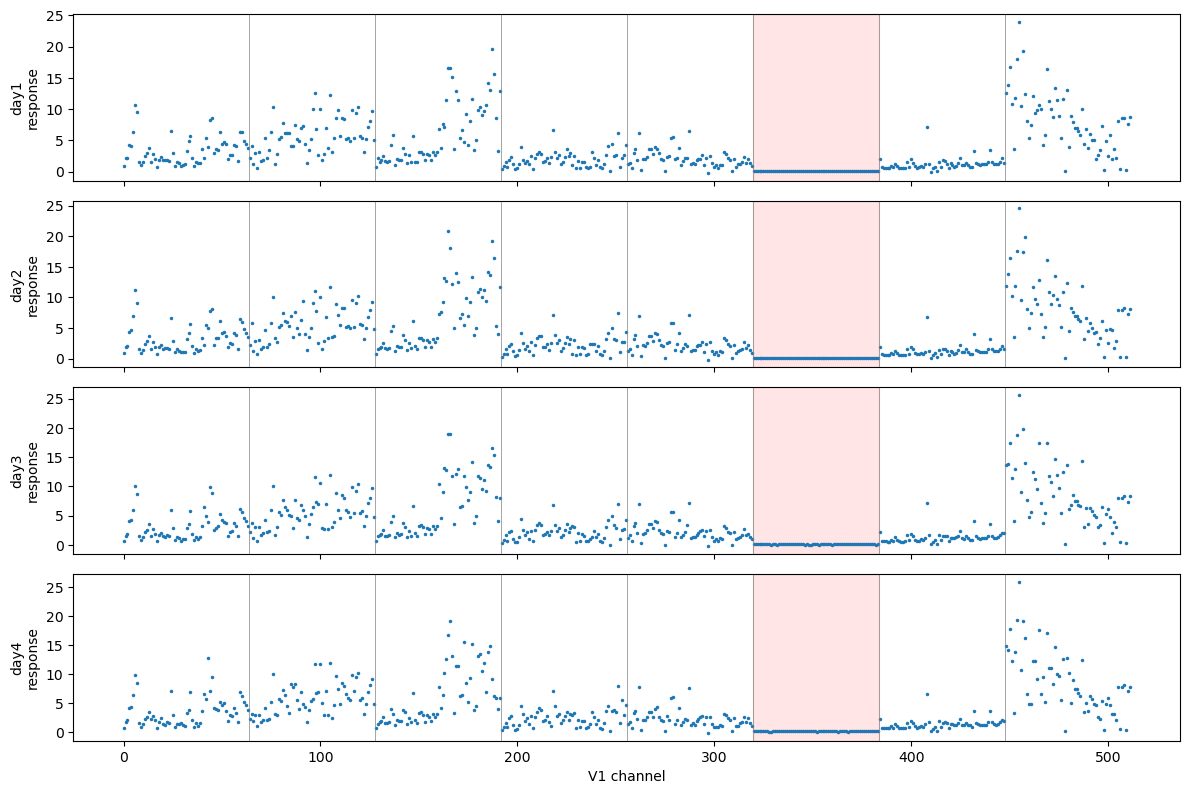

In [5]:
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)

for ax, day in zip(axes, ["day1", "day2", "day3", "day4"]):
    v1 = np.load(next(DATA.rglob(f"monkeyN_{day}_V1_binned.npz")))["binned_mua"]
    resp = v1[3:11].mean(axis=(0, 1)) - v1[:2].mean(axis=(0, 1))
    ax.plot(resp, ".", ms=3)
    ax.axvspan(319.5, 383.5, color="red", alpha=0.1)
    ax.set_ylabel(f"{day}\nresponse")
    for x in range(64, 512, 64):
        ax.axvline(x - 0.5, color="gray", lw=0.5)
    print(day, "channels 320-383: max |response| =", np.abs(resp[320:384]).max().round(3))

axes[-1].set_xlabel("V1 channel")
plt.tight_layout()
plt.show()